In [1]:
from prody import *
import glob
import os
import subprocess
import pandas as pd
from pathlib import Path
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import linkage, cophenet, fcluster, dendrogram
import json

In [91]:
def calc_ligand_rmsd(mod_structure, ref_structure, chain_align="A", chain_lig1="B", chain_lig2="C"):
    """
    Calculate ligand RMSD after aligning receptor chains.

    Args:
        mod_structure: ProDy structure of the model
        ref_structure: ProDy structure of the reference
        chain_align: chain to use for superposition (receptor)
        chain_lig: chain to calculate RMSD (ligand)

    Returns:
        rmsd_lig: RMSD value (Å) for the ligand chain after alignment
    """

    print(f"Reference mmCIF has {ref_structure.numResidues()} amino acids & {ref_structure.numAtoms()} atoms.")
    print(f"Mobile mmCIF has {mod_structure.numResidues()} amino acids & {mod_structure.numAtoms()} atoms.")

    # Select backbone atoms for alignment (C-alpha, C-beta)
    mod_align = mod_structure.select(f"chain {chain_align} and name CA")
    ref_align = ref_structure.select(f"chain {chain_align} and name CA")

    if mod_align is None or ref_align is None:
        raise ValueError(f"Cannot find chain {chain_align} in model or reference for alignment")

    # Calculate superposition
    transformation = calcTransformation(mod_align, ref_align)
    superimposed_mod = applyTransformation(transformation, mod_structure)

    # Select ligand chain atoms for RMSD
    mod_lig = superimposed_mod.select(f"(chain {chain_lig1} and name CA) or (chain {chain_lig2} and name CA)")
    ref_lig = ref_structure.select(f"(chain {chain_lig1} and name CA) or (chain {chain_lig2} and name CA)")

    # mod_lig = superimposed_mod.select(f"(chain {chain_lig1} and name CA)")
    # ref_lig = ref_structure.select(f"(chain {chain_lig1} and name CA)")

    print(f"Reference ligand has {ref_lig.numResidues()} amino acids & {ref_lig.numAtoms()} atoms.")
    print(f"Mobile ligand has {mod_lig.numResidues()} amino acids & {mod_lig.numAtoms()} atoms.")

    if mod_lig is None or ref_lig is None:
        raise ValueError(f"Cannot find chain {chain_lig1} or {chain_lig2} in model or reference for RMSD")
        # raise ValueError(f"Cannot find chain {chain_lig1} in model or reference for RMSD")

    # Calculate RMSD
    rmsd_lig = calcRMSD(ref_lig, mod_lig)

    return rmsd_lig


In [92]:
af_models = [
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1",
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_2",
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_3",
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_4"
    ]
cif_files = [cif for i in af_models for cif in glob.glob(os.path.join(i, "**/*.cif"), recursive=False)]

print(f"Found {len(cif_files)} mmCIF files for analysis.")

structures = [parsePDB(f) for f in cif_files]

# rmsd_results = np.zeros((len(cif_files), len(cif_files)))

# for i, ref_structure in enumerate(structures):
#     for j in range(i + 1, len(structures)):
#         mod_structure = structures[j]

#         rmsd_value = calc_ligand_rmsd(
#             mod_structure,
#             ref_structure,
#             chain_align="A",
#             chain_lig1="B",
#             chain_lig2="C"
#         )

#         rmsd_results[i, j] = rmsd_value
#         rmsd_results[j, i] = rmsd_value

Found 500 mmCIF files for analysis.


In [ ]:
# # create csv file with the RMSD matrix
# rmsd_df = pd.DataFrame(
#     rmsd_results, index=[Path(f).stem for f in cif_files], columns=[Path(f).stem for f in cif_files])
# rmsd_df.to_csv(
#     "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/rmsd_matrix.csv")

In [ ]:
# open rsmd csv file and create heatmap
rmsd_df = pd.read_csv(
    ("/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/500x500_rmsd_matrix.csv"), 
    index_col=0)
rmsd_results = rmsd_df.values
labels = rmsd_df.index.tolist()

In [206]:
print("Shape of RMSD matrix:", rmsd_results.shape)
# print(labels)

Shape of RMSD matrix: (500, 500)


In [ ]:
def clustering(rmsd_matrix, labels, threshold, criterion='distance'):
    from scipy.spatial.distance import squareform

    rmsd_condensed = squareform(rmsd_matrix)
    clusters = fcluster(
        linkage(rmsd_condensed, method='average'), 
        t=threshold, criterion=criterion)
    clusters_dic = {}

    for i, cluster in enumerate(clusters):
        if cluster not in clusters_dic:
            clusters_dic[cluster] = []
        clusters_dic[cluster].append(labels[i])
    cluster_centers = {}
    for cluster in clusters_dic.keys():
        cluster_indices = [i for i, c in enumerate(clusters) if c == cluster]
        cluster_rmsd = rmsd_matrix[np.ix_(cluster_indices, cluster_indices)]
        center_index = cluster_indices[np.argmin(cluster_rmsd.sum(axis=0))]
        cluster_centers[cluster] = labels[center_index]
    return clusters_dic, cluster_centers

In [ ]:
clusters_dic, cluster_centers = clustering(
    rmsd_results,
    labels=labels,
    threshold=10.0
    )

print("Number of clusters:", len(clusters_dic))
print("Clusters of models based on ligand RMSD:")
for cluster, members in clusters_dic.items():
    print(f"Length of cluster {cluster}: {len(members)}")
    print(f"Cluster {cluster}:")
    for member in members:
        print(f"  - {member}")
    print(f"  Cluster center: {cluster_centers[cluster]}")

Number of clusters: 27
Clusters of models based on ligand RMSD:
Length of cluster 14: 425
Cluster 14:
  - fold_igase_iga2_wt_seed_204865_model_2
  - fold_igase_iga2_wt_seed_204865_model_0
  - fold_igase_iga2_wt_seed_204865_model_3
  - fold_igase_iga2_wt_seed_204865_model_1
  - fold_igase_iga2_wt_seed_204865_model_4
  - fold_igase_iga2_wt_seed_471553_model_1
  - fold_igase_iga2_wt_seed_471553_model_4
  - fold_igase_iga2_wt_seed_471553_model_0
  - fold_igase_iga2_wt_seed_471553_model_3
  - fold_igase_iga2_wt_seed_978991_model_0
  - fold_igase_iga2_wt_seed_978991_model_3
  - fold_igase_iga2_wt_seed_978991_model_4
  - fold_igase_iga2_wt_seed_978991_model_1
  - fold_igase_iga2_wt_seed_978991_model_2
  - fold_igase_iga2_wt_seed_868383_model_2
  - fold_igase_iga2_wt_seed_868383_model_4
  - fold_igase_iga2_wt_seed_868383_model_0
  - fold_igase_iga2_wt_seed_868383_model_1
  - fold_igase_iga2_wt_seed_868383_model_3
  - fold_igase_iga2_wt_seed_63042_model_0
  - fold_igase_iga2_wt_seed_63042_model

In [ ]:
def extract_id(model_name):
    parts = model_name.split("_")
    seed = None
    model_num = None
    for i, part in enumerate(parts):
        if part == "seed":
            seed = parts[i + 1]
        elif part == "model":
            model_num = parts[i + 1]
    return seed, model_num

def parse_summary_confidences(json_file):
    with open(json_file, "r") as f:
        data = json.load(f)
        ptm = data["ptm"]
        iptm = data["iptm"]
        ranking_score = data["ranking_score"]
        chain_ptm = data["chain_ptm"]
        chain_iptm = data["chain_iptm"]
    return ptm, iptm, ranking_score, chain_ptm, chain_iptm

In [13]:
def save_clusters_scores_csv(clusters_dic, labels, output_file="clusters_scores.csv"):
    data = []
    for i, label in enumerate(labels):
        seed, model_num = extract_id(label)
        cluster = None
        for c, members in clusters_dic.items():
            if label in members:
                cluster = c
                break

        for i in range(1, 5):
            json_files = f"/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_{i}/igase_iga2_wt_seed_{seed}/fold_igase_iga2_wt_seed_{seed}_summary_confidences_{model_num}.json"
            if os.path.exists(json_files):
                json_file = json_files
                break
        else:
            print(f"File not found for label: {label}")
            continue

        ptm, iptm, ranking_score, chain_ptm, chain_iptm = parse_summary_confidences(json_file)
        
        data.append({
            "model": label,
            "cluster": cluster,
            "pTM": ptm,
            "ipTM": iptm,
            "ranking_score": ranking_score,
            "chainA_ptm": chain_ptm[0],
            "chainB_ptm": chain_ptm[1],
            "chainC_ptm": chain_ptm[2],
            "chainA_iptm": chain_iptm[0],
            "chainB_iptm": chain_iptm[1],
            "chainC_iptm": chain_iptm[2]
        })

    df = pd.DataFrame(data)
    df.to_csv(output_file, index=False)

def save_centroids(cluster_centers):
    with open("cluster_centroids.txt", "w") as f:
        for cluster, centroid in cluster_centers.items():
            f.write(f"Cluster {cluster}: {centroid}\n")

In [15]:
save_clusters_scores_csv(clusters_dic, labels=labels, output_file="clusters_scores.csv")
save_centroids(cluster_centers)

In [ ]:
good_clusters = clusters_dic[14] + clusters_dic[15]
print("Good clusters:", good_clusters)

Good clusters: ['fold_igase_iga2_wt_seed_204865_model_2', 'fold_igase_iga2_wt_seed_204865_model_0', 'fold_igase_iga2_wt_seed_204865_model_3', 'fold_igase_iga2_wt_seed_204865_model_1', 'fold_igase_iga2_wt_seed_204865_model_4', 'fold_igase_iga2_wt_seed_471553_model_1', 'fold_igase_iga2_wt_seed_471553_model_4', 'fold_igase_iga2_wt_seed_471553_model_0', 'fold_igase_iga2_wt_seed_471553_model_3', 'fold_igase_iga2_wt_seed_978991_model_0', 'fold_igase_iga2_wt_seed_978991_model_3', 'fold_igase_iga2_wt_seed_978991_model_4', 'fold_igase_iga2_wt_seed_978991_model_1', 'fold_igase_iga2_wt_seed_978991_model_2', 'fold_igase_iga2_wt_seed_868383_model_2', 'fold_igase_iga2_wt_seed_868383_model_4', 'fold_igase_iga2_wt_seed_868383_model_0', 'fold_igase_iga2_wt_seed_868383_model_1', 'fold_igase_iga2_wt_seed_868383_model_3', 'fold_igase_iga2_wt_seed_63042_model_0', 'fold_igase_iga2_wt_seed_63042_model_4', 'fold_igase_iga2_wt_seed_63042_model_2', 'fold_igase_iga2_wt_seed_63042_model_1', 'fold_igase_iga2_wt_se

In [96]:
# Generic helpers to compute distances for any pair of atom selections.
def min_atom_distance(structure, selection_a, selection_b):
    """Return minimum atom-atom distance between two ProDy selections in one structure."""
    atoms_a = structure.select(selection_a)
    atoms_b = structure.select(selection_b)

    if atoms_a is None or atoms_b is None:
        return np.nan

    coords_a = atoms_a.getCoords()
    coords_b = atoms_b.getCoords()
    dmat = np.linalg.norm(coords_a[:, None, :] - coords_b[None, :, :], axis=-1)
    return float(np.min(dmat))


def get_cluster_member_indices(labels, cluster_members):
    """Return indices of labels that belong to the requested cluster members."""
    cluster_set = set(cluster_members)
    return [i for i, label in enumerate(labels) if label in cluster_set]


def distance_by_model(structures, labels, files, indices, selection_a, selection_b):
    """Compute one distance (A vs B) per model and return a list of dict records.
    We will add an excpetion for certain models that have swapped chain names.
    If the model is in the exception list, we will swap chain E with D for the ZN selection.
    If not, we will use the original selection.
    """
    label_exceptions = {
    "fold_igase_iga2_wt_seed_868383_model_0",
    "fold_igase_iga2_wt_seed_701058_model_2",
    "fold_igase_iga2_wt_seed_770407_model_2",
    "fold_igase_iga2_wt_seed_770407_model_0",
    "fold_igase_iga2_wt_seed_287828_model_3",
    "fold_igase_iga2_wt_seed_231596_model_3",
    }
    records = []

    for i in indices:
        sel_a = selection_a
        sel_b = selection_b
        if labels[i] in label_exceptions:
            if sel_a == "chain E and name ZN":
                sel_a = "chain D and name ZN"
            if sel_b == "chain E and name ZN":
                sel_b = "chain D and name ZN"
        records.append({
            "model": labels[i],
            "file": files[i],
            "distance": min_atom_distance(structures[i], sel_a, sel_b),
        })

    return records


In [ ]:
# 1) Define the subset of complexes to analyze.
good_cluster_members = clusters_dic[14] + clusters_dic[15]
indices_good = get_cluster_member_indices(labels, good_cluster_members)

In [103]:
# Fig. name = "P223toZn"
af3_zn_catalytic = "chain E and name ZN"
precat_zn_catalytic = "chain E and name ZN and resnum 999"
recog_zn_catalytic = "chain E and name ZN and resnum 999"

af3_pro223 = "chain B and resnum 223 and resname PRO and name C"
precat_pro223 = "chain H and resnum 223 and resname PRO and name C"
recog_pro223 = "chain H and resnum 223 and resname PRO and name C"

# Cα P194 (IgA) to Cα C198 (IgA)
# Fig. name = "P194toC198"
af3_pro194 = "chain B and resnum 194 and resname PRO and name CA"
precat_pro194 = "chain H and resnum 194 and resname PRO and name CA"
recog_pro194 = "chain H and resnum 194 and resname PRO and name CA"

af3_cys198 = "chain B and resnum 198 and resname CYS and name CA"
precat_cys198 = "chain H and resnum 198 and resname CYS and name CA"
recog_cys198 = "chain H and resnum 198 and resname CYS and name CA"

# Cα Asp200 (IgA) to Cα Lys564 (IgAse)
# Fig. name = "Asp200toLys564"
af3_asp200 = "chain B and resnum 200 and resname ASP and name CA"
precat_asp200 = "chain H and resnum 200 and resname ASP and name CA"
recog_asp200 = "chain H and resnum 200 and resname ASP and name CA"

af3_lys564 = "chain A and resnum 237 and resname LYS and name CA"
precat_lys564 = "chain E and resnum 564 and resname LYS and name CA"
recog_lys564 = "chain E and resnum 564 and resname LYS and name CA"

# Cα Cys198 (IgA) to Cα Cys222 (IgA)
# Fig. name = "C198toC222"
af3_cys222 = "chain B and resnum 222 and resname CYS and name CA"
precat_cys222 = "chain H and resnum 222 and resname CYS and name CA"
recog_cys222 = "chain H and resnum 222 and resname CYS and name CA"

# Cα Cys434 (IgAse) to Cα Cys127 (IgA)
# Fig. name = "C434toC127"
af3_cys434 = "chain A and resnum 107 and resname ASP and name CA"
precat_cys434 = "chain E and resnum 434 and resname CYS and name CA"
recog_cys434 = "chain E and resnum 434 and resname CYS and name CA"

af3_cys127 = "chain C and resnum 127 and resname SER and name CA"
precat_cys127 = "chain L and resnum 127 and resname CYS and name CA"
recog_cys127 = "chain L and resnum 127 and resname CYS and name CA"

In [ ]:
# AF3 models
# Get the structures and labels
af3_cluster_members = clusters_dic[14] + clusters_dic[15]
af3_indices = get_cluster_member_indices(labels, af3_cluster_members)

# Compute distances for the four pairs of selections in the AF3 models
P223toZn_AF3 = distance_by_model(
    structures=structures, labels=labels,
    files=cif_files, indices=af3_indices,
    selection_a=af3_pro223,
    selection_b=af3_zn_catalytic,)
P194toC198_AF3 = distance_by_model(
    structures=structures, labels=labels,
    files=cif_files, indices=af3_indices,
    selection_a=af3_pro194,
    selection_b=af3_cys198,)
Asp200toLys564_AF3 = distance_by_model(
    structures=structures, labels=labels,
    files=cif_files, indices=af3_indices,
    selection_a=af3_asp200,
    selection_b=af3_lys564,)
Cys198toCys222_AF3 = distance_by_model(
    structures=structures, labels=labels,
    files=cif_files, indices=af3_indices,
    selection_a=af3_cys198,
    selection_b=af3_cys222,)
Cys434toCys127_AF3 = distance_by_model(
    structures=structures, labels=labels,
    files=cif_files, indices=af3_indices,
    selection_a=af3_cys434,
    selection_b=af3_cys127,)

# Store AF3 distances in DataFrames
df_P223toZn_AF3 = pd.DataFrame(P223toZn_AF3).rename(
    columns={"distance": "P223toZn_distance"})
df_P194toC198_AF3 = pd.DataFrame(P194toC198_AF3).rename(
    columns={"distance": "P194toC198_distance"})
df_Asp200toLys564_AF3 = pd.DataFrame(Asp200toLys564_AF3).rename(
    columns={"distance": "Asp200toLys564_distance"})
df_Cys198toCys222_AF3 = pd.DataFrame(Cys198toCys222_AF3).rename(
    columns={"distance": "Cys198toCys222_distance"})
df_Cys434toCys127_AF3 = pd.DataFrame(Cys434toCys127_AF3).rename(
    columns={"distance": "Cys434toCys127_distance"})
print("complexes analyzed in AF3 clusters:", len(af3_indices))
# df_P223toZn_AF3.to_csv("/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/P223toZn_AF3_distances.csv", index=False)
# df_P194toC198_AF3.to_csv("/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/P194toC198_AF3_distances.csv", index=False)
# df_Asp200toLys564_AF3.to_csv("/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Asp200toLys564_AF3_distances.csv", index=False)
# df_Cys198toCys222_AF3.to_csv("/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Cys198toCys222_AF3_distances.csv", index=False)
# df_Cys434toCys127_AF3.to_csv("/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Cys434toCys127_AF3_distances.csv", index=False)

complexes analyzed in AF3 clusters: 443


In [ ]:
df_P223toZn_AF3 = pd.read_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/P223toZn_AF3_distances.csv")
df_P194toC198_AF3 = pd.read_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/P194toC198_AF3_distances.csv")
df_Asp200toLys564_AF3 = pd.read_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Asp200toLys564_AF3_distances.csv")
df_Cys198toCys222_AF3 = pd.read_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Cys198toCys222_AF3_distances.csv")
df_Cys434toCys127_AF3 = pd.read_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Cys434toCys127_AF3_distances.csv")

In [109]:
# Experimental structures
# Final experimental structures so i can compare with the predictions
precat_pdb = "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/analysis/IgAse23-Fabpr_precat_last.pdb"
recog_pdb = "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/analysis/IgAse23-Fabpr_recog_last.pdb"
precat_structure = parsePDB(precat_pdb)
recog_structure = parsePDB(recog_pdb)

P223toZn_dist = {
    "Precatalytic": min_atom_distance(
        precat_structure, precat_pro223, precat_zn_catalytic),
    "Recognition": min_atom_distance(
        recog_structure, recog_pro223, recog_zn_catalytic)}
P194toC198_dist = {
    "Precatalytic": min_atom_distance(
        precat_structure, precat_pro194, precat_cys198),
    "Recognition": min_atom_distance(
        recog_structure, recog_pro194, recog_cys198)}
Asp200toLys564_dist = {
    "Precatalytic": min_atom_distance(
        precat_structure, precat_asp200, precat_lys564),
    "Recognition": min_atom_distance(
        recog_structure, recog_asp200, recog_lys564)}
Cys198toCys222_dist = {
    "Precatalytic": min_atom_distance(
        precat_structure, precat_cys198, precat_cys222),
    "Recognition": min_atom_distance(
        recog_structure, recog_cys198, recog_cys222)}
Cys434toCys127_dist = {
    "Precatalytic": min_atom_distance(
        precat_structure, precat_cys434, precat_cys127),
    "Recognition": min_atom_distance(
        recog_structure, recog_cys434, recog_cys127)}

print("P223 to Zn distances:")
for state, dist in P223toZn_dist.items():
    print(f"  - {state}: {dist:.2f} Å")
print("P194 to C198 distances:")
for state, dist in P194toC198_dist.items():
    print(f"  - {state}: {dist:.2f} Å")
print("Asp200 to Lys564 distances:")
for state, dist in Asp200toLys564_dist.items():
    print(f"  - {state}: {dist:.2f} Å")
print("Cys198 to Cys222 distances:")
for state, dist in Cys198toCys222_dist.items():
    print(f"  - {state}: {dist:.2f} Å")
print("Cys434 to Cys127 distances:")
for state, dist in Cys434toCys127_dist.items():
    print(f"  - {state}: {dist:.2f} Å")

P223 to Zn distances:
  - Precatalytic: 7.47 Å
  - Recognition: 13.21 Å
P194 to C198 distances:
  - Precatalytic: 10.79 Å
  - Recognition: 8.19 Å
Asp200 to Lys564 distances:
  - Precatalytic: 6.51 Å
  - Recognition: 15.66 Å
Cys198 to Cys222 distances:
  - Precatalytic: 6.01 Å
  - Recognition: 6.21 Å
Cys434 to Cys127 distances:
  - Precatalytic: 5.72 Å
  - Recognition: 5.59 Å


In [ ]:
# Add experimental distances to DataFrames for comparison
precat_records = [
        {"model": "Precatalytic",
        "file": precat_pdb,
        "P223toZn_distance": P223toZn_dist["Precatalytic"],
        "P194toC198_distance": P194toC198_dist["Precatalytic"],
        "Asp200toLys564_distance": Asp200toLys564_dist["Precatalytic"],
        "Cys198toCys222_distance": Cys198toCys222_dist["Precatalytic"],
        "Cys434toCys127_distance": Cys434toCys127_dist["Precatalytic"],
        },
        {"model": "Recognition",
        "file": recog_pdb,
        "P223toZn_distance": P223toZn_dist["Recognition"],
        "P194toC198_distance": P194toC198_dist["Recognition"],
        "Asp200toLys564_distance": Asp200toLys564_dist["Recognition"],
        "Cys198toCys222_distance": Cys198toCys222_dist["Recognition"],
        "Cys434toCys127_distance": Cys434toCys127_dist["Recognition"],
        },
]

df_precat_recog = pd.DataFrame(precat_records)

df_P223toZn_glob = pd.concat(
    [df_P223toZn_AF3, df_precat_recog[["model", "file", "P223toZn_distance"]]],
    ignore_index=True)
df_P194toC198_glob = pd.concat(
    [df_P194toC198_AF3, df_precat_recog[["model", "file", "P194toC198_distance"]]],
    ignore_index=True)
df_Asp200toLys564_glob = pd.concat(
    [df_Asp200toLys564_AF3, df_precat_recog[["model", "file", "Asp200toLys564_distance"]]],
    ignore_index=True)
df_Cys198toCys222_glob = pd.concat(
    [df_Cys198toCys222_AF3, df_precat_recog[["model", "file", "Cys198toCys222_distance"]]],
    ignore_index=True)
df_Cys434toCys127_glob = pd.concat(
    [df_Cys434toCys127_AF3, df_precat_recog[["model", "file", "Cys434toCys127_distance"]]],
    ignore_index=True)

df_P223toZn_glob.to_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/P223toZn_global_distances.csv", index=False)
df_P194toC198_glob.to_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/P194toC198_global_distances.csv", index=False)
df_Asp200toLys564_glob.to_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Asp200toLys564_global_distances.csv", index=False)
df_Cys198toCys222_glob.to_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Cys198toCys222_global_distances.csv", index=False)
df_Cys434toCys127_glob.to_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Cys434toCys127_global_distances.csv", index=False)

In [ ]:
df_P223toZn_glob = pd.read_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/P223toZn_global_distances.csv")
df_P194toC198_glob = pd.read_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/P194toC198_global_distances.csv")
df_Asp200toLys564_glob = pd.read_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Asp200toLys564_global_distances.csv")
df_Cys198toCys222_glob = pd.read_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Cys198toCys222_global_distances.csv")
df_Cys434toCys127_glob = pd.read_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Cys434toCys127_global_distances.csv")

In [ ]:
# df_P223toZn_glob
# print("Mean distances for P223 to Zn catalytic site of the AF3 models:")
# # take in account the models that start with fold*... not, Recognition or Precatalytic
# af3_models_only = df_P223toZn_glob[~df_P223toZn_glob["model"].isin(["Precatalytic", "Recognition"])]
# mean_distance = af3_models_only["P223toZn_distance"].mean()
# std_distance = af3_models_only["P223toZn_distance"].std()
# print(f"  - Mean: {mean_distance:.2f} Å")
# print(f"  - Std: {std_distance:.2f} Å")

Mean distances for P223 to Zn catalytic site of the AF3 models:
  - Mean: 12.07 Å
  - Std: 0.50 Å


In [337]:
def plot_distance_pair(
    df_x, xcol, df_y, ycol,
    fig_title=None, xlabel=None, ylabel=None,
    savefig=False, set_legend=False,
    models=None, fig_w=5, fig_h=4,
    lim_x=None, lim_y=None,
    precat_size=175,
    recog_size=150,
    af3_size=50,
    multiple_locator=True
):
    from matplotlib.lines import Line2D
    from matplotlib.font_manager import fontManager, FontProperties
    from matplotlib.ticker import MultipleLocator

    font_path = "/home/gaecri/Documents/Projects/Utils/Fonts/DIN_Condensed_Bold.ttf"
    fontManager.addfont(font_path)
    prop = FontProperties(fname=font_path)
    sns.set_theme(style="ticks", font=prop.get_name())

    if models is None:
        models = ["Precatalytic", "Recognition", "AF3 Models"]

    plot_df = pd.DataFrame({
        "x": df_x[xcol].values,
        "y": df_y[ycol].values,
        "model": df_x["model"].values,})

    plot_df["group"] = np.where(
        plot_df["model"] == "Precatalytic",
        "Precatalytic",
        np.where(
            plot_df["model"] == "Recognition",
            "Recognition",
            "AF3 Models"))

    plot_df = plot_df[plot_df["group"].isin(models)].copy()

    palette = {
        "Precatalytic": "#7ce07c",
        "Recognition": "#cc5a5c",
        "AF3 Models": "#1f7fc3",}
    markers = {
        "Precatalytic": "^",
        "Recognition": "s",
        "AF3 Models": "o",}
    point_sizes = {
        "Precatalytic": precat_size,
        "Recognition": recog_size,
        "AF3 Models": af3_size,}

    plot_df["size"] = plot_df["group"].map(point_sizes)

    plt.figure(figsize=(fig_w, fig_h), dpi=150)

    sns.scatterplot(
        data=plot_df,
        x="x",
        y="y",
        hue="group",
        size="size",
        sizes=(
            min(point_sizes.values()),
            max(point_sizes.values())),
        palette=palette,
        style="group",
        markers=markers,
        legend=False,
    )

    ax = plt.gca()

    if multiple_locator:
        ax.set_aspect("equal", adjustable="box")

    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.yaxis.set_major_locator(MultipleLocator(2))

    custom_handles = [
        Line2D(
            [0], [0],
            marker=markers[group],
            color="w",
            label=group,
            markerfacecolor=palette[group],
            markersize=np.sqrt(point_sizes[group])*1.0,)
        for group in models]

    if set_legend:
        plt.legend(
            handles=custom_handles,
            borderpad=0.3,
            markerscale=0.9,
            title_fontsize=8,
            # title="Model Type",
            facecolor="white",
            framealpha=1.0,
            edgecolor="gray",)

    plt.title(
        fig_title if fig_title else None,
        fontsize=16,)

    plt.xlabel(
        xlabel if xlabel else xcol.replace("_", " "),
        fontsize=14,)
    plt.ylabel(
        ylabel if ylabel else ycol.replace("_", " "),
        fontsize=14,)

    if lim_x is not None:
        plt.xlim(lim_x)
    if lim_y is not None:
        plt.ylim(lim_y)

    plt.grid(True, linestyle="-", alpha=0.5)
    plt.tight_layout()

    if savefig:
        fname = (
            fig_title.replace(" ", "_")
            if fig_title
            else f"{xcol}_vs_{ycol}")
        plt.savefig(f"./plots/{fname}.png", dpi=350)
        plt.savefig(f"./plots/{fname}.pdf", dpi=350)
        plt.savefig(f"./plots/{fname}.svg", dpi=350)

    plt.show()

In [ ]:
def get_model_legend_handles(
    models=None,
    precat_size=175,
    recog_size=150,
    af3_size=50,):
    from matplotlib.lines import Line2D

    if models is None:
        models = ["Precatalytic", "Recognition", "AF3 Models"]
    palette = {
        "Precatalytic": "#7ce07c",
        "Recognition": "#cc5a5c",
        "AF3 Models": "#1f7fc3",}
    markers = {
        "Precatalytic": "^",
        "Recognition": "s",
        "AF3 Models": "o",}
    point_sizes = {
        "Precatalytic": precat_size,
        "Recognition": recog_size,
        "AF3 Models": af3_size,}
    return [
        Line2D(
            [0], [0],
            marker=markers[group],
            color="w",
            label=group,
            markerfacecolor=palette[group],
            markersize=np.sqrt(point_sizes[group]),
            markeredgewidth=0.5,
            markeredgecolor="black",)
        for group in models
    ]


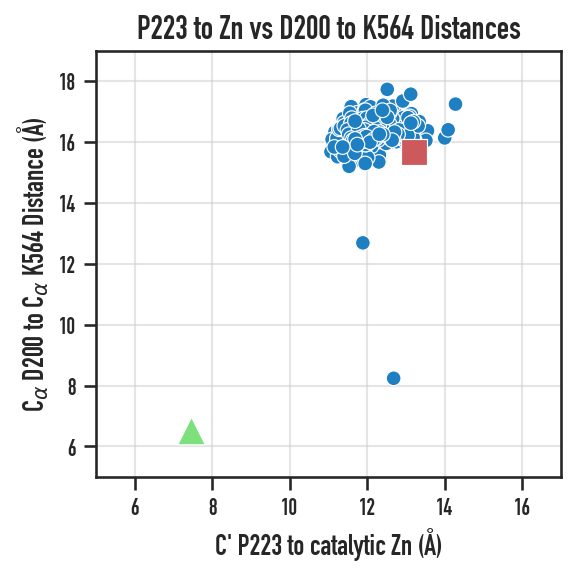

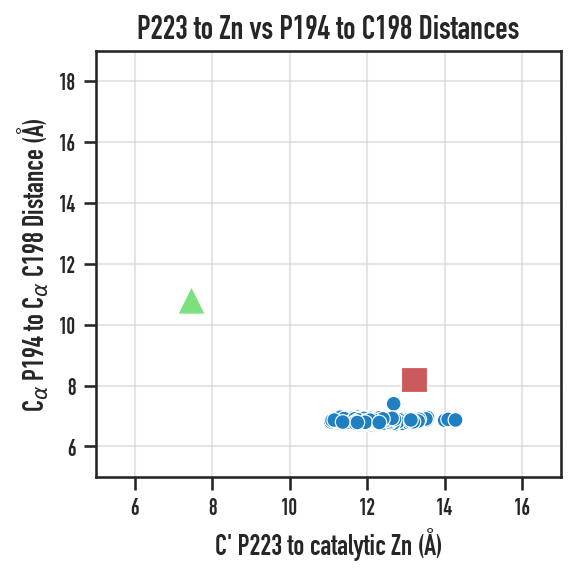

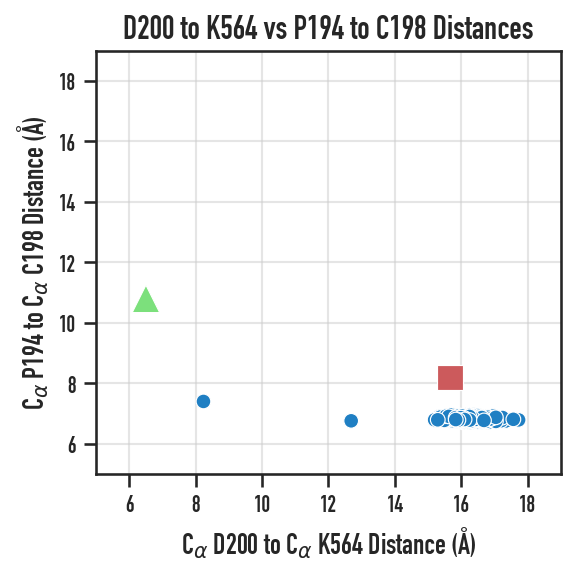

In [344]:
plot_distance_pair(
    df_x=df_P223toZn_glob,
    xcol="P223toZn_distance",
    df_y=df_Asp200toLys564_glob,
    ycol="Asp200toLys564_distance",
    fig_title="P223 to Zn vs D200 to K564 Distances",
    xlabel="C' P223 to catalytic Zn (Å)",
    ylabel="C$_\\alpha$ D200 to C$_\\alpha$ K564 Distance (Å)",
    savefig=True,
    # set_legend=True,
    models=None,
    fig_w=4, fig_h=4,
    # lim_x=(5, 21), lim_y=(5, 21)
    lim_x=(5, 17), lim_y=(5, 19),
    multiple_locator=False,
    )
plot_distance_pair(
    df_x=df_P223toZn_glob,
    xcol="P223toZn_distance",
    df_y=df_P194toC198_glob,
    ycol="P194toC198_distance",
    fig_title="P223 to Zn vs P194 to C198 Distances",
    xlabel="C' P223 to catalytic Zn (Å)",
    ylabel="C$_\\alpha$ P194 to C$_\\alpha$ C198 Distance (Å)",
    savefig=True,
    # set_legend=True,
    models=None,
    fig_w=4, fig_h=4,
    # lim_x=(5, 21), lim_y=(5, 21)
    lim_x=(5, 17), lim_y=(5, 19),
    multiple_locator=False,
    )
plot_distance_pair(
    df_y=df_P194toC198_glob,
    ycol="P194toC198_distance",
    df_x=df_Asp200toLys564_glob,
    xcol="Asp200toLys564_distance",
    fig_title="D200 to K564 vs P194 to C198 Distances",
    ylabel="C$_\\alpha$ P194 to C$_\\alpha$ C198 Distance (Å)",
    xlabel="C$_\\alpha$ D200 to C$_\\alpha$ K564 Distance (Å)",
    savefig=True,
    # set_legend=True,
    models=None,
    fig_w=4, fig_h=4,
    lim_x=(5, 19), lim_y=(5, 19),
    multiple_locator=False,
    )

In [124]:
def plot_rmsd_dist(
    rmsd_data, precat, recog,
    fig_title="Ligand RMSD Distribution",
    xlabel="Ligand RMSD (Å)", ylabel="Frequency",
    savefig=False,
    fig_w=5, fig_h=5,
    set_legend=False,):
    """plot a distribution of rmsd values for AF3 models and the recog and precat"""
    from matplotlib.font_manager import fontManager, FontProperties
    font_path = "/home/gaecri/Documents/Projects/Utils/Fonts/DIN_Condensed_Bold.ttf"
    fontManager.addfont(font_path)
    prop = FontProperties(fname=font_path)
    sns.set_theme(style="whitegrid", font=prop.get_name())

    plt.figure(figsize=(fig_w, fig_h), dpi=200)

    sns.histplot(
        data=rmsd_data,
        x="ligand_RMSD",
        hue="model",
        bins=362,
        # kde=True,
        palette={
            "Precatalytic": "#90ee90",
            "Recognition": "#cc5a5c",
            "AF3 Model": "#1f7fc3",},
        alpha=0.6,
        edgecolor="black",
        linewidth=0.5,
        legend=set_legend
    )

    # plot a vertical line for the precatalytic and recognition ligand RMSD values
    plt.axvline(precat, color="#90ee90", linestyle="--", label=f"Precatalytic RMSD: {precat:.2f} Å")
    plt.axvline(recog, color="#cc5a5c", linestyle="--", label=f"Recognition RMSD: {recog:.2f} Å")

    # plot a vertical line at 25A to show the threshold for good models
    # plt.axvline(25, color="red", linestyle=":", label="RMSD Threshold: 25 Å")

    if set_legend:
        plt.legend(
            title="", 
            fontsize=10, title_fontsize=12, loc="upper right",
            labels=[
                "AF3 Models",
                f"Precatalytic",
                f"Recognition",
                "RMSD Threshold"
            ])
    # plt.xlim(-5, max(rmsd_data["ligand_RMSD"].max(), recog + 5))
    # plt.xlim(-1, 40)
    plt.xlim(-.5, 8)
    plt.ylim(0, 200)
    # plt.xticks(range(0, 41, 10))
    plt.yticks(range(0, 201, 50))
    plt.title(fig_title, fontsize=16)
    plt.xlabel(xlabel, fontsize=14)
    plt.ylabel(ylabel, fontsize=14)
    if savefig:
        fname = fig_title.replace(" ", "_")
        plt.savefig(f"{fname}.png", dpi=300)
        plt.savefig(f"{fname}.pdf", dpi=300)
    plt.tight_layout()
    plt.show()


In [ ]:
# Now I will do the same but adding ALL models from AF3, not only those in the good ones.
# We can use clusters_dic to get all indices
af3_all_cluster_members = []
for cluster_id in clusters_dic.keys():
    af3_all_cluster_members.extend(clusters_dic[cluster_id])
# print(len(af3_all_cluster_members))
af3_all_indices = get_cluster_member_indices(labels, af3_all_cluster_members)
# print("complexes analyzed in all AF3 clusters:", len(af3_all_indices))

# Compute distances for the four pairs of selections in ALL AF3 models
# Compute distances for the four pairs of selections in the AF3 models
P223toZn_AF3 = distance_by_model(
    structures=structures, labels=labels,
    files=cif_files, indices=af3_all_indices,
    selection_a=af3_pro223,
    selection_b=af3_zn_catalytic,)
P194toC198_AF3 = distance_by_model(
    structures=structures, labels=labels,
    files=cif_files, indices=af3_all_indices,
    selection_a=af3_pro194,
    selection_b=af3_cys198,)
Asp200toLys564_AF3 = distance_by_model(
    structures=structures, labels=labels,
    files=cif_files, indices=af3_all_indices,
    selection_a=af3_asp200,
    selection_b=af3_lys564,)
Cys198toCys222_AF3 = distance_by_model(
    structures=structures, labels=labels,
    files=cif_files, indices=af3_all_indices,
    selection_a=af3_cys198,
    selection_b=af3_cys222,)
Cys434toCys127_AF3 = distance_by_model(
    structures=structures, labels=labels,
    files=cif_files, indices=af3_all_indices,
    selection_a=af3_cys434,
    selection_b=af3_cys127,)

# Store ALL AF3 distances in DataFrames
df_P223toZn_AF3_all = pd.DataFrame(P223toZn_AF3).rename(
    columns={"distance": "P223toZn_distance"})
df_P194toC198_AF3_all = pd.DataFrame(P194toC198_AF3).rename(
    columns={"distance": "P194toC198_distance"})
df_Asp200toLys564_AF3_all = pd.DataFrame(Asp200toLys564_AF3).rename(
    columns={"distance": "Asp200toLys564_distance"})
df_Cys198toCys222_AF3_all = pd.DataFrame(Cys198toCys222_AF3).rename(
    columns={"distance": "Cys198toCys222_distance"})
df_Cys434toCys127_AF3_all = pd.DataFrame(Cys434toCys127_AF3).rename(
    columns={"distance": "Cys434toCys127_distance"})
print("complexes analyzed in all AF3 clusters:", len(af3_all_indices))
# df_P223toZn_AF3_all
# df_P194toC198_AF3_all
# df_Asp200toLys564_AF3_all
# df_Cys198toCys222_AF3_all
# df_Cys434toCys127_AF3_all
df_P223toZn_AF3_all.to_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/P223toZn_AF3_all_distances.csv", index=False)
df_P194toC198_AF3_all.to_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/P194toC198_AF3_all_distances.csv", index=False)
df_Asp200toLys564_AF3_all.to_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Asp200toLys564_AF3_all_distances.csv", index=False)
df_Cys198toCys222_AF3_all.to_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Cys198toCys222_AF3_all_distances.csv", index=False)
df_Cys434toCys127_AF3_all.to_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Cys434toCys127_AF3_all_distances.csv", index=False)

complexes analyzed in all AF3 clusters: 500


In [ ]:
df_P223toZn_all_glob = pd.concat(
    [df_P223toZn_AF3_all, df_precat_recog[["model", "file", "P223toZn_distance"]]],
    ignore_index=True)
df_P194toC198_all_glob = pd.concat(
    [df_P194toC198_AF3_all, df_precat_recog[["model", "file", "P194toC198_distance"]]],
    ignore_index=True)
df_Asp200toLys564_all_glob = pd.concat(
    [df_Asp200toLys564_AF3_all, df_precat_recog[["model", "file", "Asp200toLys564_distance"]]],
    ignore_index=True)
df_Cys198toCys222_all_glob = pd.concat(
    [df_Cys198toCys222_AF3_all, df_precat_recog[["model", "file", "Cys198toCys222_distance"]]],
    ignore_index=True)
df_Cys434toCys127_all_glob = pd.concat(
    [df_Cys434toCys127_AF3_all, df_precat_recog[["model", "file", "Cys434toCys127_distance"]]],
    ignore_index=True)

df_P223toZn_all_glob.to_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/P223toZn_all_global_distances.csv", index=False)
df_P194toC198_all_glob.to_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/P194toC198_all_global_distances.csv", index=False)
df_Asp200toLys564_all_glob.to_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Asp200toLys564_all_global_distances.csv", index=False)
df_Cys198toCys222_all_glob.to_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Cys198toCys222_all_global_distances.csv", index=False)
df_Cys434toCys127_all_glob.to_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Cys434toCys127_all_global_distances.csv", index=False)

In [ ]:
df_P223toZn_all_glob = pd.read_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/P223toZn_all_global_distances.csv")
df_P194toC198_all_glob = pd.read_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/P194toC198_all_global_distances.csv")
df_Asp200toLys564_all_glob = pd.read_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Asp200toLys564_all_global_distances.csv")
df_Cys198toCys222_all_glob = pd.read_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Cys198toCys222_all_global_distances.csv")
df_Cys434toCys127_all_glob = pd.read_csv(
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/Cys434toCys127_all_global_distances.csv")

In [131]:
def calc_ligand_rmsd_cryo(mod_structure, ref_structure, 
                        mod_chain_align,  ref_chain_align,
                        mod_chain_lig1, ref_chain_lig1,
                        mod_chain_lig2, ref_chain_lig2,
                        mod_res_align, ref_res_align,
                        mod_res_lig1, ref_res_lig1,
                        mod_res_lig2, ref_res_lig2,
                        verbose=True
                        ):
    """
    Calculate ligand RMSD after aligning receptor chains.

    Args:
        mod_structure: ProDy structure of the model
        ref_structure: ProDy structure of the reference
        mod_chain_align: chain to use for superposition (model)
        ref_chain_align: chain to use for superposition (reference)
        mod_chain_lig1: chain to calculate RMSD (ligand)
        ref_chain_lig1: chain to calculate RMSD (ligand)
        mod_chain_lig2: chain to calculate RMSD (ligand)
        ref_chain_lig2: chain to calculate RMSD (ligand)
        mod_res_align: residue range for alignment (model)
        ref_res_align: residue range for alignment (reference)
        mod_res_lig1: residue range for ligand 1 (model)
        ref_res_lig1: residue range for ligand 1 (reference)
        mod_res_lig2: residue range for ligand 2 (model)
        ref_res_lig2: residue range for ligand 2 (reference)

    Returns:
        rmsd_lig: RMSD value (Å) for the ligand chain after alignment
    """

    if verbose:
        print(f"Reference mmCIF has {ref_structure.numResidues()} amino acids & {ref_structure.numAtoms()} atoms.")
    if verbose:
        print(f"Mobile mmCIF has {mod_structure.numResidues()} amino acids & {mod_structure.numAtoms()} atoms.")

    if verbose:
        for chain in np.unique(mod_structure.getChids()):
            print("CHAIN:", repr(chain))
            sel = mod_structure.select(f"chain {chain} and name CA")
            print("SEL:", sel)

    # Select backbone atoms for alignment (C-alpha)
    mod_align = mod_structure.select(f"chain {mod_chain_align} and name CA and resnum {mod_res_align}")
    ref_align = ref_structure.select(f"chain {ref_chain_align} and name CA and resnum {ref_res_align}")

    if verbose:
        print(mod_align)
        print(ref_align)
        print(mod_align.numAtoms())
        print(ref_align.numAtoms())

    # Calculate superposition
    transformation = calcTransformation(mod_align, ref_align)
    superimposed_mod = applyTransformation(transformation, mod_structure)

    if verbose:
        print("After superposition:")
        print(id(mod_structure))
        print(id(ref_structure))
        print(id(superimposed_mod))

    # Select ligand chain atoms for RMSD (two chains as ligand is dimeric)
    mod_lig = superimposed_mod.select(
        f"(chain {mod_chain_lig1} and name CA and resnum {mod_res_lig1}) or "
        f"(chain {mod_chain_lig2} and name CA and resnum {mod_res_lig2})"
    )

    ref_lig = ref_structure.select(
        f"(chain {ref_chain_lig1} and name CA and resnum {ref_res_lig1}) or "
        f"(chain {ref_chain_lig2} and name CA and resnum {ref_res_lig2})"
    )
    if verbose:
        print(f"Reference ligand has {ref_lig.numResidues()} amino acids & {ref_lig.numAtoms()} atoms.")
        print(f"Mobile ligand has {mod_lig.numResidues()} amino acids & {mod_lig.numAtoms()} atoms.")
        print(ref_lig.numAtoms())
        print(mod_lig.numAtoms())

        print(ref_lig.getResnums()[:10])
        print(mod_lig.getResnums()[:10])
    # Calculate RMSD
    rmsd_lig = calcRMSD(ref_lig, mod_lig)

    return rmsd_lig

In [132]:
# reference structure for RMSD calculation: precatalytic structure
# mobile strucures: all AF3 + precatalytic + recognition
# align on IgAse, calculate on Fab (both chains together). define all atoms:
precat_chain_align = "E" # IgAse
precat_res_align = "330:806"
precat_chain_fab1 = "H" # IgA
precat_res_fab1 = "2:225" # Full Fab1
precat_res_fab1_cnt = "124:225" # Constant part
precat_chain_fab2 = "L" # IgA
precat_res_fab2 = "2:214" # Full Fab2
precat_res_fab2_cnt = "115:214" # Constant part
recog_chain_align = "E" # IgAse
recog_res_align = "330:806"
recog_chain_fab1 = "H" # IgA
recog_res_fab1 = "2:225" # Full Fab1
recog_res_fab1_cnt = "124:225" # Constant part
recog_chain_fab2 = "L" # IgA
recog_res_fab2 = "2:214" # Full Fab2
recog_res_fab2_cnt = "115:214" # Constant part
af3_chain_align = "A" # IgAse
af3_res_align = "3:479"
af3_chain_fab1 = "B" # IgA
af3_res_fab1 = "2:225" # Full Fab1
af3_res_fab1_cnt = "124:225" # Constant part
af3_chain_fab2 = "C" # IgA
af3_res_fab2 = "2:214" # Full Fab2
af3_res_fab2_cnt = "115:214" # Constant part

In [133]:
# Precatalytic over Precatalytic (Full Fab)
print("Checking atom counts for precatalytic structure chain H:",
    precat_structure.select(
        "chain H and name CA and resnum 2:225"
    ).numAtoms())
print("Checking atom counts for precatalytic structure chain L:",
    precat_structure.select(
        "chain L and name CA and resnum 2:214"
    ).numAtoms())

# Calculate ligand RMSD for precatalytic structures
precat_over_precat_rmsd = calc_ligand_rmsd_cryo(
        mod_structure = precat_structure,
        ref_structure = precat_structure,
        mod_chain_align = precat_chain_align,
        ref_chain_align = precat_chain_align,
        mod_chain_lig1 = precat_chain_fab1,
        ref_chain_lig1 = precat_chain_fab1,
        mod_chain_lig2 = precat_chain_fab2,
        ref_chain_lig2 = precat_chain_fab2,
        mod_res_align = precat_res_align,
        ref_res_align = precat_res_align,
        mod_res_lig1 = precat_res_fab1,
        ref_res_lig1 = precat_res_fab1,
        mod_res_lig2 = precat_res_fab2,
        ref_res_lig2 = precat_res_fab2,
        verbose=False,
)
print(f"Precatalytic ligand RMSD (vs itself): {precat_over_precat_rmsd:.2f} Å")

Checking atom counts for precatalytic structure chain H: 223
Checking atom counts for precatalytic structure chain L: 212
Precatalytic ligand RMSD (vs itself): 0.00 Å


In [134]:
# Precatalytic over Precatalytic (Constant Fab)
print("Checking atom counts for precatalytic structure chain H:",
    precat_structure.select(
        "chain H and name CA and resnum 2:225"
    ).numAtoms())
print("Checking atom counts for precatalytic structure chain L:",
    precat_structure.select(
        "chain L and name CA and resnum 2:214"
    ).numAtoms())

# Calculate ligand RMSD for precatalytic structures
precat_over_precat_rmsd_const = calc_ligand_rmsd_cryo(
        mod_structure = precat_structure,
        ref_structure = precat_structure,
        mod_chain_align = precat_chain_align,
        ref_chain_align = precat_chain_align,
        mod_chain_lig1 = precat_chain_fab1,
        ref_chain_lig1 = precat_chain_fab1,
        mod_chain_lig2 = precat_chain_fab2,
        ref_chain_lig2 = precat_chain_fab2,
        mod_res_align = precat_res_align,
        ref_res_align = precat_res_align,
        mod_res_lig1 = precat_res_fab1_cnt,
        ref_res_lig1 = precat_res_fab1_cnt,
        mod_res_lig2 = precat_res_fab2_cnt,
        ref_res_lig2 = precat_res_fab2_cnt,
        verbose=False,
)
print(f"Precatalytic ligand RMSD (vs itself): {precat_over_precat_rmsd_const:.2f} Å")

Checking atom counts for precatalytic structure chain H: 223
Checking atom counts for precatalytic structure chain L: 212
Precatalytic ligand RMSD (vs itself): 0.00 Å


In [135]:
# Recognition over Precatalytic (Full Fab)
print("Checking atom counts for recognition structure chain H:",
    recog_structure.select(
        "chain H and name CA and resnum 2:225"
    ).numAtoms())
print("Checking atom counts for recognition structure chain L:",
    recog_structure.select(
        "chain L and name CA and resnum 2:214"
    ).numAtoms())

# Calculate ligand RMSD for recognition structure
recog_over_precat_rmsd = calc_ligand_rmsd_cryo(
        mod_structure = recog_structure,
        ref_structure = precat_structure,
        mod_chain_align = recog_chain_align,
        ref_chain_align = precat_chain_align,
        mod_chain_lig1 = recog_chain_fab1,
        ref_chain_lig1 = precat_chain_fab1,
        mod_chain_lig2 = recog_chain_fab2,
        ref_chain_lig2 = precat_chain_fab2,
        mod_res_align = recog_res_align,
        ref_res_align = precat_res_align,
        mod_res_lig1 = recog_res_fab1,
        ref_res_lig1 = precat_res_fab1,
        mod_res_lig2 = recog_res_fab2,
        ref_res_lig2 = precat_res_fab2,
        verbose=False,
)
print(f"Recognition ligand RMSD (vs precatalytic): {recog_over_precat_rmsd:.2f} Å")

Checking atom counts for recognition structure chain H: 223
Checking atom counts for recognition structure chain L: 212
Recognition ligand RMSD (vs precatalytic): 4.57 Å


In [136]:
# Recognition over Precatalytic (Constant Fab)
print("Checking atom counts for recognition structure chain H:",
    recog_structure.select(
        "chain H and name CA and resnum 2:225"
    ).numAtoms())
print("Checking atom counts for recognition structure chain L:",
    recog_structure.select(
        "chain L and name CA and resnum 2:214"
    ).numAtoms())

# Calculate ligand RMSD for recognition structure
recog_over_precat_rmsd_const = calc_ligand_rmsd_cryo(
        mod_structure = recog_structure,
        ref_structure = precat_structure,
        mod_chain_align = recog_chain_align,
        ref_chain_align = precat_chain_align,
        mod_chain_lig1 = recog_chain_fab1,
        ref_chain_lig1 = precat_chain_fab1,
        mod_chain_lig2 = recog_chain_fab2,
        ref_chain_lig2 = precat_chain_fab2,
        mod_res_align = recog_res_align,
        ref_res_align = precat_res_align,
        mod_res_lig1 = recog_res_fab1_cnt,
        ref_res_lig1 = precat_res_fab1_cnt,
        mod_res_lig2 = recog_res_fab2_cnt,
        ref_res_lig2 = precat_res_fab2_cnt,
        verbose=False,
)
print(f"Recognition ligand RMSD (vs precatalytic): {recog_over_precat_rmsd_const:.2f} Å")

Checking atom counts for recognition structure chain H: 223
Checking atom counts for recognition structure chain L: 212
Recognition ligand RMSD (vs precatalytic): 3.30 Å


In [140]:
# Precatalytic over Recognition (Full Fab)
print("Checking atom counts for precatalytic structure chain H:",
    precat_structure.select(
        "chain H and name CA and resnum 2:225"
    ).numAtoms())
print("Checking atom counts for precatalytic structure chain L:",
    precat_structure.select(
        "chain L and name CA and resnum 2:214"
    ).numAtoms())

# Calculate ligand RMSD for recognition structure
precat_over_recog_rmsd = calc_ligand_rmsd_cryo(
        mod_structure = precat_structure,
        ref_structure = recog_structure,
        mod_chain_align = precat_chain_align,
        ref_chain_align = recog_chain_align,
        mod_chain_lig1 = precat_chain_fab1,
        ref_chain_lig1 = recog_chain_fab1,
        mod_chain_lig2 = precat_chain_fab2,
        ref_chain_lig2 = recog_chain_fab2,
        mod_res_align = precat_res_align,
        ref_res_align = recog_res_align,
        mod_res_lig1 = precat_res_fab1,
        ref_res_lig1 = recog_res_fab1,
        mod_res_lig2 = precat_res_fab2,
        ref_res_lig2 = recog_res_fab2,
        verbose=False,
)
print(f"Precatalytic ligand RMSD (vs recognition): {precat_over_recog_rmsd:.2f} Å")

Checking atom counts for precatalytic structure chain H: 223
Checking atom counts for precatalytic structure chain L: 212
Precatalytic ligand RMSD (vs recognition): 4.57 Å


In [141]:
# Precatalytic over Recognition (Constant Fab)
print("Checking atom counts for precatalytic structure chain H:",
    precat_structure.select(
        "chain H and name CA and resnum 2:225"
    ).numAtoms())
print("Checking atom counts for precatalytic structure chain L:",
    precat_structure.select(
        "chain L and name CA and resnum 2:214"
    ).numAtoms())

# Calculate ligand RMSD for recognition structure
precat_over_recog_rmsd_const = calc_ligand_rmsd_cryo(
        mod_structure = precat_structure,
        ref_structure = recog_structure,
        mod_chain_align = precat_chain_align,
        ref_chain_align = recog_chain_align,
        mod_chain_lig1 = precat_chain_fab1,
        ref_chain_lig1 = recog_chain_fab1,
        mod_chain_lig2 = precat_chain_fab2,
        ref_chain_lig2 = recog_chain_fab2,
        mod_res_align = precat_res_align,
        ref_res_align = recog_res_align,
        mod_res_lig1 = precat_res_fab1_cnt,
        ref_res_lig1 = recog_res_fab1_cnt,
        mod_res_lig2 = precat_res_fab2_cnt,
        ref_res_lig2 = recog_res_fab2_cnt,
        verbose=False,
)
print(f"Precatalytic ligand RMSD (vs recognition): {precat_over_recog_rmsd_const:.2f} Å")

Checking atom counts for precatalytic structure chain H: 223
Checking atom counts for precatalytic structure chain L: 212
Precatalytic ligand RMSD (vs recognition): 3.30 Å


In [143]:
# Recognition over Recognition (Full Fab)
print("Checking atom counts for recognition structure chain H:",
    recog_structure.select(
        "chain H and name CA and resnum 2:225"
    ).numAtoms())
print("Checking atom counts for recognition structure chain L:",
    recog_structure.select(
        "chain L and name CA and resnum 2:214"
    ).numAtoms())

# Calculate ligand RMSD for recognition structure
recog_over_recog_rmsd = calc_ligand_rmsd_cryo(
        mod_structure = recog_structure,
        ref_structure = recog_structure,
        mod_chain_align = recog_chain_align,
        ref_chain_align = recog_chain_align,
        mod_chain_lig1 = recog_chain_fab1,
        ref_chain_lig1 = recog_chain_fab1,
        mod_chain_lig2 = recog_chain_fab2,
        ref_chain_lig2 = recog_chain_fab2,
        mod_res_align = recog_res_align,
        ref_res_align = recog_res_align,
        mod_res_lig1 = recog_res_fab1,
        ref_res_lig1 = recog_res_fab1,
        mod_res_lig2 = recog_res_fab2,
        ref_res_lig2 = recog_res_fab2,
        verbose=False,
)
print(f"Recognition ligand RMSD (vs itself): {recog_over_recog_rmsd:.2f} Å")

Checking atom counts for recognition structure chain H: 223
Checking atom counts for recognition structure chain L: 212
Recognition ligand RMSD (vs itself): 0.00 Å


In [144]:
# Recognition over Recognition (Constant Fab)
print("Checking atom counts for recognition structure chain H:",
    recog_structure.select(
        "chain H and name CA and resnum 2:225"
    ).numAtoms())
print("Checking atom counts for recognition structure chain L:",
    recog_structure.select(
        "chain L and name CA and resnum 2:214"
    ).numAtoms())

# Calculate ligand RMSD for recognition structure
recog_over_recog_rmsd_const = calc_ligand_rmsd_cryo(
        mod_structure = recog_structure,
        ref_structure = recog_structure,
        mod_chain_align = recog_chain_align,
        ref_chain_align = recog_chain_align,
        mod_chain_lig1 = recog_chain_fab1,
        ref_chain_lig1 = recog_chain_fab1,
        mod_chain_lig2 = recog_chain_fab2,
        ref_chain_lig2 = recog_chain_fab2,
        mod_res_align = recog_res_align,
        ref_res_align = recog_res_align,
        mod_res_lig1 = recog_res_fab1_cnt,
        ref_res_lig1 = recog_res_fab1_cnt,
        mod_res_lig2 = recog_res_fab2_cnt,
        ref_res_lig2 = recog_res_fab2_cnt,
        verbose=False,
)
print(f"Recognition ligand RMSD (vs itself): {recog_over_recog_rmsd_const:.2f} Å")

Checking atom counts for recognition structure chain H: 223
Checking atom counts for recognition structure chain L: 212
Recognition ligand RMSD (vs itself): 0.00 Å


In [ ]:
# AF3 models vs Precatalytic (Full Fab)
af3_over_precat = []
for idx in af3_all_indices:
    if idx == 0:
        print(
            "Chain and residue counts for AF3 model structure:",
            structures[idx].select("chain B and name CA and resnum 2:225").numAtoms()
        )
    mod_structure = structures[idx]
    mod_file = cif_files[idx]
    lig_rmsd = calc_ligand_rmsd_cryo(
        mod_structure = mod_structure,
        ref_structure = precat_structure,
        mod_chain_align = af3_chain_align,
        ref_chain_align = precat_chain_align,
        mod_chain_lig1 = af3_chain_fab1,
        ref_chain_lig1 = precat_chain_fab1,
        mod_chain_lig2 = af3_chain_fab2,
        ref_chain_lig2 = precat_chain_fab2,
        mod_res_align = af3_res_align,
        ref_res_align = precat_res_align,
        mod_res_lig1 = af3_res_fab1,
        ref_res_lig1 = precat_res_fab1,
        mod_res_lig2 = af3_res_fab2,
        ref_res_lig2 = precat_res_fab2,
        verbose=False,
    )
    af3_over_precat.append({
        "model": "AF3 Model",
        "file": mod_file,
        "ligand_RMSD": lig_rmsd})
    print(f"AF3 model {mod_file} ligand RMSD (vs precatalytic):\n\t{lig_rmsd:.2f} Å")


Chain and residue counts for AF3 model structure: 223
AF3 model /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_204865/fold_igase_iga2_wt_seed_204865_model_2.cif ligand RMSD (vs precatalytic):
	17.50 Å
AF3 model /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_204865/fold_igase_iga2_wt_seed_204865_model_0.cif ligand RMSD (vs precatalytic):
	16.10 Å
AF3 model /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_204865/fold_igase_iga2_wt_seed_204865_model_3.cif ligand RMSD (vs precatalytic):
	17.05 Å
AF3 model /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_204865/fold_igase_iga2_wt_seed_204865_model_1.cif ligand RMSD (vs precatalytic):
	17.71 Å
AF3 model /home/gaecri/Documents/Projects/

In [146]:
# AF3 vs Precatalytic metrics (Full Fab)
af3_lig_rmsd_values_precat = [entry["ligand_RMSD"] for entry in af3_over_precat]
max_rmsd = max(af3_lig_rmsd_values_precat)
min_rmsd = min(af3_lig_rmsd_values_precat)
median_rmsd = np.median(af3_lig_rmsd_values_precat)
print(f"AF3 ligand RMSD - Max: {max_rmsd:.2f} Å, Min: {min_rmsd:.2f} Å, Median: {median_rmsd:.2f} Å")
for entry in af3_over_precat:
    if entry["ligand_RMSD"] == max_rmsd:
        print(f"Model with max RMSD: {entry['file']} (RMSD: {entry['ligand_RMSD']:.2f} Å)")
    if entry["ligand_RMSD"] == min_rmsd:
        print(f"Model with min RMSD: {entry['file']} (RMSD: {entry['ligand_RMSD']:.2f} Å)")

print("Number of models with ligand RMSD < 25 Å:", 
    sum(1 for entry in af3_over_precat if entry["ligand_RMSD"] < 25))

AF3 ligand RMSD - Max: 121.49 Å, Min: 2.27 Å, Median: 20.36 Å
Model with max RMSD: /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_3/igase_iga2_wt_seed_120516/fold_igase_iga2_wt_seed_120516_model_4.cif (RMSD: 121.49 Å)
Model with min RMSD: /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_4/igase_iga2_wt_seed_793319/fold_igase_iga2_wt_seed_793319_model_4.cif (RMSD: 2.27 Å)
Number of models with ligand RMSD < 25 Å: 443


In [ ]:
# AF3 models vs Precatalytic (Constant Fab)
af3_over_precat_const = []
for idx in af3_all_indices:
    if idx == 0:
        print(
            "Chain and residue counts for AF3 model structure:",
            structures[idx].select("chain B and name CA and resnum 2:225").numAtoms()
        )
    mod_structure = structures[idx]
    mod_file = cif_files[idx]
    lig_rmsd = calc_ligand_rmsd_cryo(
        mod_structure = mod_structure,
        ref_structure = precat_structure,
        mod_chain_align = af3_chain_align,
        ref_chain_align = precat_chain_align,
        mod_chain_lig1 = af3_chain_fab1,
        ref_chain_lig1 = precat_chain_fab1,
        mod_chain_lig2 = af3_chain_fab2,
        ref_chain_lig2 = precat_chain_fab2,
        mod_res_align = af3_res_align,
        ref_res_align = precat_res_align,
        mod_res_lig1 = af3_res_fab1_cnt,
        ref_res_lig1 = precat_res_fab1_cnt,
        mod_res_lig2 = af3_res_fab2_cnt,
        ref_res_lig2 = precat_res_fab2_cnt,
        verbose=False,
    )
    af3_over_precat_const.append({
        "model": "AF3 Model",
        "file": mod_file,
        "ligand_RMSD": lig_rmsd})
    print(f"AF3 model {mod_file} ligand RMSD (vs precatalytic):\n\t{lig_rmsd:.2f} Å")


Chain and residue counts for AF3 model structure: 223
AF3 model /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_204865/fold_igase_iga2_wt_seed_204865_model_2.cif ligand RMSD (vs precatalytic):
	2.34 Å
AF3 model /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_204865/fold_igase_iga2_wt_seed_204865_model_0.cif ligand RMSD (vs precatalytic):
	2.00 Å
AF3 model /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_204865/fold_igase_iga2_wt_seed_204865_model_3.cif ligand RMSD (vs precatalytic):
	2.15 Å
AF3 model /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_204865/fold_igase_iga2_wt_seed_204865_model_1.cif ligand RMSD (vs precatalytic):
	2.01 Å
AF3 model /home/gaecri/Documents/Projects/IgAs

In [148]:
# AF3 vs Precatalytic metrics (Constant Fab)
af3_lig_rmsd_values_precat_const = [entry["ligand_RMSD"] for entry in af3_over_precat_const]
max_rmsd = max(af3_lig_rmsd_values_precat_const)
min_rmsd = min(af3_lig_rmsd_values_precat_const)
median_rmsd = np.median(af3_lig_rmsd_values_precat_const)
print(f"AF3 ligand RMSD - Max: {max_rmsd:.2f} Å, Min: {min_rmsd:.2f} Å, Median: {median_rmsd:.2f} Å")
for entry in af3_over_precat_const:
    if entry["ligand_RMSD"] == max_rmsd:
        print(f"Model with max RMSD: {entry['file']} (RMSD: {entry['ligand_RMSD']:.2f} Å)")
    if entry["ligand_RMSD"] == min_rmsd:
        print(f"Model with min RMSD: {entry['file']} (RMSD: {entry['ligand_RMSD']:.2f} Å)")

print("Number of models with ligand RMSD < 25 Å:", 
    sum(1 for entry in af3_over_precat_const if entry["ligand_RMSD"] < 25))

AF3 ligand RMSD - Max: 117.81 Å, Min: 1.69 Å, Median: 2.22 Å
Model with min RMSD: /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_74684/fold_igase_iga2_wt_seed_74684_model_1.cif (RMSD: 1.69 Å)
Model with max RMSD: /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_3/igase_iga2_wt_seed_120516/fold_igase_iga2_wt_seed_120516_model_4.cif (RMSD: 117.81 Å)
Number of models with ligand RMSD < 25 Å: 443


In [ ]:
# AF3 models vs Recognition (Full Fab)
af3_over_recog = []
for idx in af3_all_indices:
    if idx == 0:
        print(
            "Chain and residue counts for AF3 model structure:",
            structures[idx].select("chain B and name CA and resnum 2:225").numAtoms()
        )
    mod_structure = structures[idx]
    mod_file = cif_files[idx]
    lig_rmsd = calc_ligand_rmsd_cryo(
        mod_structure = mod_structure,
        ref_structure = recog_structure,
        mod_chain_align = af3_chain_align,
        ref_chain_align = recog_chain_align,
        mod_chain_lig1 = af3_chain_fab1,
        ref_chain_lig1 = recog_chain_fab1,
        mod_chain_lig2 = af3_chain_fab2,
        ref_chain_lig2 = recog_chain_fab2,
        mod_res_align = af3_res_align,
        ref_res_align = recog_res_align,
        mod_res_lig1 = af3_res_fab1,
        ref_res_lig1 = recog_res_fab1,
        mod_res_lig2 = af3_res_fab2,
        ref_res_lig2 = recog_res_fab2,
        verbose=False,
    )
    af3_over_recog.append({
        "model": "AF3 Model",
        "file": mod_file,
        "ligand_RMSD": lig_rmsd})
    print(f"AF3 model {mod_file} ligand RMSD (vs recognition):\n\t{lig_rmsd:.2f} Å")


Chain and residue counts for AF3 model structure: 223
AF3 model /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_204865/fold_igase_iga2_wt_seed_204865_model_2.cif ligand RMSD (vs recognition):
	17.59 Å
AF3 model /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_204865/fold_igase_iga2_wt_seed_204865_model_0.cif ligand RMSD (vs recognition):
	16.23 Å
AF3 model /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_204865/fold_igase_iga2_wt_seed_204865_model_3.cif ligand RMSD (vs recognition):
	16.86 Å
AF3 model /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_204865/fold_igase_iga2_wt_seed_204865_model_1.cif ligand RMSD (vs recognition):
	17.73 Å
AF3 model /home/gaecri/Documents/Projects/IgAs

In [150]:
# AF3 vs Recognition metrics (Full Fab)
af3_lig_rmsd_values_recog = [entry["ligand_RMSD"] for entry in af3_over_recog]
max_rmsd = max(af3_lig_rmsd_values_recog)
min_rmsd = min(af3_lig_rmsd_values_recog)
median_rmsd = np.median(af3_lig_rmsd_values_recog)
print(f"AF3 ligand RMSD - Max: {max_rmsd:.2f} Å, Min: {min_rmsd:.2f} Å, Median: {median_rmsd:.2f} Å")
for entry in af3_over_recog:
    if entry["ligand_RMSD"] == max_rmsd:
        print(f"Model with max RMSD: {entry['file']} (RMSD: {entry['ligand_RMSD']:.2f} Å)")
    if entry["ligand_RMSD"] == min_rmsd:
        print(f"Model with min RMSD: {entry['file']} (RMSD: {entry['ligand_RMSD']:.2f} Å)")

print("Number of models with ligand RMSD < 26 Å:", 
    sum(1 for entry in af3_over_recog if entry["ligand_RMSD"] < 26))

AF3 ligand RMSD - Max: 123.32 Å, Min: 5.06 Å, Median: 20.30 Å
Model with max RMSD: /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_3/igase_iga2_wt_seed_120516/fold_igase_iga2_wt_seed_120516_model_4.cif (RMSD: 123.32 Å)
Model with min RMSD: /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_4/igase_iga2_wt_seed_793319/fold_igase_iga2_wt_seed_793319_model_4.cif (RMSD: 5.06 Å)
Number of models with ligand RMSD < 26 Å: 443


In [ ]:
# AF3 models vs Recognition (Constant Fab)
af3_over_recog_const = []
for idx in af3_all_indices:
    if idx == 0:
        print(
            "Chain and residue counts for AF3 model structure:",
            structures[idx].select("chain B and name CA and resnum 2:225").numAtoms()
        )
    mod_structure = structures[idx]
    mod_file = cif_files[idx]
    lig_rmsd = calc_ligand_rmsd_cryo(
        mod_structure = mod_structure,
        ref_structure = recog_structure,
        mod_chain_align = af3_chain_align,
        ref_chain_align = recog_chain_align,
        mod_chain_lig1 = af3_chain_fab1,
        ref_chain_lig1 = recog_chain_fab1,
        mod_chain_lig2 = af3_chain_fab2,
        ref_chain_lig2 = recog_chain_fab2,
        mod_res_align = af3_res_align,
        ref_res_align = recog_res_align,
        mod_res_lig1 = af3_res_fab1_cnt,
        ref_res_lig1 = recog_res_fab1_cnt,
        mod_res_lig2 = af3_res_fab2_cnt,
        ref_res_lig2 = recog_res_fab2_cnt,
        verbose=False,
    )
    af3_over_recog_const.append({
        "model": "AF3 Model",
        "file": mod_file,
        "ligand_RMSD": lig_rmsd})
    print(f"AF3 model {mod_file} ligand RMSD (vs recognition):\n\t{lig_rmsd:.2f} Å")


Chain and residue counts for AF3 model structure: 223
AF3 model /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_204865/fold_igase_iga2_wt_seed_204865_model_2.cif ligand RMSD (vs recognition):
	3.59 Å
AF3 model /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_204865/fold_igase_iga2_wt_seed_204865_model_0.cif ligand RMSD (vs recognition):
	3.51 Å
AF3 model /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_204865/fold_igase_iga2_wt_seed_204865_model_3.cif ligand RMSD (vs recognition):
	3.09 Å
AF3 model /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_204865/fold_igase_iga2_wt_seed_204865_model_1.cif ligand RMSD (vs recognition):
	3.53 Å
AF3 model /home/gaecri/Documents/Projects/IgAses/I

In [152]:
# AF3 vs Recognition metrics (Constant Fab)
af3_lig_rmsd_values_recog_const = [entry["ligand_RMSD"] for entry in af3_over_recog_const]
max_rmsd = max(af3_lig_rmsd_values_recog_const)
min_rmsd = min(af3_lig_rmsd_values_recog_const)
median_rmsd = np.median(af3_lig_rmsd_values_recog_const)
print(f"AF3 ligand RMSD - Max: {max_rmsd:.2f} Å, Min: {min_rmsd:.2f} Å, Median: {median_rmsd:.2f} Å")
for entry in af3_over_recog_const:
    if entry["ligand_RMSD"] == max_rmsd:
        print(f"Model with max RMSD: {entry['file']} (RMSD: {entry['ligand_RMSD']:.2f} Å)")
    if entry["ligand_RMSD"] == min_rmsd:
        print(f"Model with min RMSD: {entry['file']} (RMSD: {entry['ligand_RMSD']:.2f} Å)")

print("Number of models with ligand RMSD < 26 Å:", 
    sum(1 for entry in af3_over_recog_const if entry["ligand_RMSD"] < 26))

AF3 ligand RMSD - Max: 119.80 Å, Min: 1.99 Å, Median: 3.43 Å
Model with min RMSD: /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_988943/fold_igase_iga2_wt_seed_988943_model_3.cif (RMSD: 1.99 Å)
Model with max RMSD: /home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_3/igase_iga2_wt_seed_120516/fold_igase_iga2_wt_seed_120516_model_4.cif (RMSD: 119.80 Å)
Number of models with ligand RMSD < 26 Å: 443


In [397]:
def plot_rmsd_dist(
    rmsd_data, precat, recog,
    fig_title="Ligand RMSD Distribution",
    xlabel="Ligand RMSD (Å)", ylabel="Frequency",
    savefig=True, fig_w=5, fig_h=5,
    set_legend=False, set_title=True):
    """plot a distribution of rmsd values for AF3 models and the recog and precat"""
    from matplotlib.font_manager import fontManager, FontProperties
    font_path = "/home/gaecri/Documents/Projects/Utils/Fonts/DIN_Condensed_Bold.ttf"
    fontManager.addfont(font_path)
    prop = FontProperties(fname=font_path)
    sns.set_theme(style="whitegrid", font=prop.get_name())

    plt.figure(figsize=(fig_w, fig_h), dpi=200)

    sns.histplot(
        # limit data to ligand RMSD values less than 40A for better visualization
        # data=rmsd_data[rmsd_data["ligand_RMSD"] < 40],
        data=rmsd_data,
        x="ligand_RMSD", hue="model",
        bins=62,
        # bins=320,
        # bins=12,
        # kde=True,
        palette={
            "Precatalytic": "#7ce07c",
            "Recognition": "#cc5a5c",
            "AF3 Model": "#1f7fc3",},
        alpha=0.7,
        edgecolor="black", linewidth=0.5,
        legend=set_legend)

    # plot a vertical line for the precatalytic and recognition ligand RMSD values
    plt.axvline(precat, color="#7ce07c", linestyle="--", label=f"Precatalytic RMSD: {precat:.2f} Å")
    plt.axvline(recog, color="#cc5a5c", linestyle="--", label=f"Recognition RMSD: {recog:.2f} Å")

    # plot a vertical line at 25A to show the threshold for good models
    # plt.axvline(25, color="red", linestyle=":", label="RMSD Threshold: 25 Å")

    if set_legend:
        plt.legend(
            title="", 
            fontsize=10, title_fontsize=12, loc="upper right",
            labels=[
                "AF3 Models",
                f"Precatalytic",
                f"Recognition",
                "RMSD Threshold"])
    # plt.xlim(-5, max(rmsd_data["ligand_RMSD"].max(), recog + 5))
    plt.xlim(-1, 40)
    # plt.xlim(-.25, 8)
    plt.ylim(0, 200)
    plt.xticks(range(0, 41, 10))
    plt.yticks(range(0, 201, 50))
    if set_title:
        plt.title(fig_title, fontsize=16)
    # plt.xlabel(xlabel, fontsize=14)
    # plt.ylabel(ylabel, fontsize=14)
    plt.xlabel("")
    plt.ylabel("")
    plt.tight_layout()
    if savefig:
        fname = fig_title.replace(" ", "_")
        plt.savefig(f"{fname}.png", dpi=350)
        plt.savefig(f"{fname}.pdf", dpi=350)

    plt.show()


In [ ]:
# Plot AF3 + Recog over Precat (Full Fab)
# Prepare data for plotting
rmsd_df = pd.DataFrame(af3_over_precat)
rmsd_df = pd.concat([
    rmsd_df,
    pd.DataFrame([{
        "model": "Precatalytic",
        "file": "precatalytic_structure",
        "ligand_RMSD": precat_over_precat_rmsd}]),
    pd.DataFrame([{
        "model": "Recognition",
        "file": "recognition_structure",
        "ligand_RMSD": recog_over_precat_rmsd}]),
], ignore_index=True)
print(rmsd_df.head())

In [ ]:
# Plot AF3 + Recog over Precat (Constant Fab)
# Prepare data for plotting
rmsd_df = pd.DataFrame(af3_over_precat_const)
rmsd_df = pd.concat([
    rmsd_df,
    pd.DataFrame([{
        "model": "Precatalytic",
        "file": "precatalytic_structure",
        "ligand_RMSD": precat_over_precat_rmsd_const}]),
    pd.DataFrame([{
        "model": "Recognition",
        "file": "recognition_structure",
        "ligand_RMSD": recog_over_precat_rmsd_const}]),
], ignore_index=True)
print(rmsd_df.head())

       model                                               file  ligand_RMSD
0  AF3 Model  /home/gaecri/Documents/Projects/IgAses/IgAse_I...    17.590135
1  AF3 Model  /home/gaecri/Documents/Projects/IgAses/IgAse_I...    16.228825
2  AF3 Model  /home/gaecri/Documents/Projects/IgAses/IgAse_I...    16.860318
3  AF3 Model  /home/gaecri/Documents/Projects/IgAses/IgAse_I...    17.733383
4  AF3 Model  /home/gaecri/Documents/Projects/IgAses/IgAse_I...    18.413092


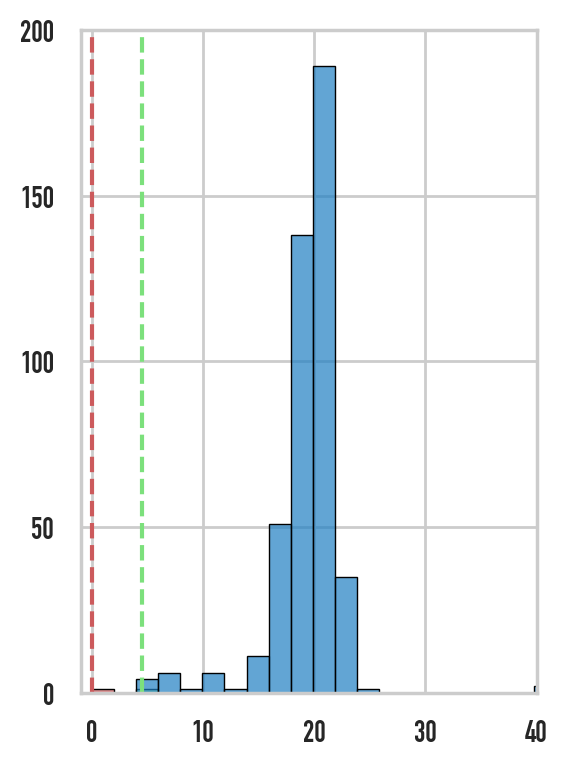

In [398]:
# Plot AF3 + Precat over Recog (Full Fab)
# Prepare data for plotting
rmsd_df = pd.DataFrame(af3_over_recog)
rmsd_df = pd.concat([
    rmsd_df,
    pd.DataFrame([{
        "model": "Precatalytic",
        "file": "precatalytic_structure",
        "ligand_RMSD": precat_over_recog_rmsd}]),
    pd.DataFrame([{
        "model": "Recognition",
        "file": "recognition_structure",
        "ligand_RMSD": recog_over_recog_rmsd}]),
], ignore_index=True)
print(rmsd_df.head())
plot_rmsd_dist(
    rmsd_df, 
    precat=precat_over_recog_rmsd,
    recog=recog_over_recog_rmsd,
    fig_title="Ligand RMSD (AF3 Models and Precat vs Recog) - Full",
    savefig=True,set_title=False,
    fig_w=3, fig_h=4,)

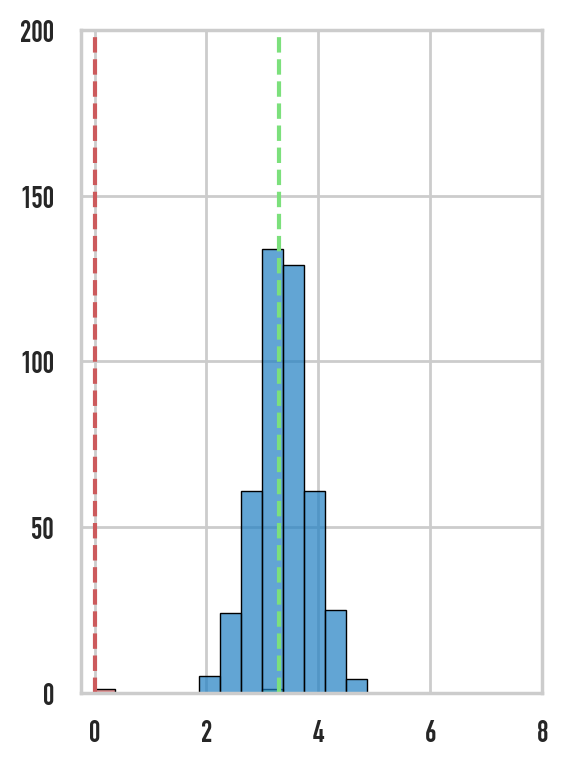

In [396]:
# Plot AF3 + Precat over Recog (Constant Fab)
# Prepare data for plotting
rmsd_df = pd.DataFrame(af3_over_recog_const)
rmsd_df = pd.concat([
    rmsd_df,
    pd.DataFrame([{
        "model": "Precatalytic",
        "file": "precatalytic_structure",
        "ligand_RMSD": precat_over_recog_rmsd_const}]),
    pd.DataFrame([{
        "model": "Recognition",
        "file": "recognition_structure",
        "ligand_RMSD": recog_over_recog_rmsd_const}]),
], ignore_index=True)
rmsd_df
plot_rmsd_dist(
    rmsd_df, 
    precat=precat_over_recog_rmsd_const,
    recog=recog_over_recog_rmsd_const,
    fig_title="Ligand RMSD (AF3 Models and Precat vs Recog) - Const",
    savefig=True, set_title=False,
    fig_w=3, fig_h=4,)

In [158]:
#LigandRMSDvsCys434toCys127 (Full Fab) - Over Precat
# Prepare data for plotting
Cys434toCys127_rmsd_df = pd.DataFrame(af3_over_precat)
Cys434toCys127_rmsd_df = pd.concat([
    Cys434toCys127_rmsd_df,
    pd.DataFrame([{
        "model": "Precatalytic",
        "file": "precatalytic_structure",
        "ligand_RMSD": precat_over_precat_rmsd}]),
    pd.DataFrame([{
        "model": "Recognition",
        "file": "recognition_structure",
        "ligand_RMSD": recog_over_precat_rmsd}]),
], ignore_index=True)

In [160]:
#LigandRMSDvsCys434toCys127 (Constant Fab) - Over Precat
# Prepare data for plotting
Cys434toCys127_rmsd_df = pd.DataFrame(af3_over_precat_const)
Cys434toCys127_rmsd_df = pd.concat([
    Cys434toCys127_rmsd_df,
    pd.DataFrame([{
        "model": "Precatalytic",
        "file": "precatalytic_structure",
        "ligand_RMSD": precat_over_precat_rmsd_const}]),
    pd.DataFrame([{
        "model": "Recognition",
        "file": "recognition_structure",
        "ligand_RMSD": recog_over_precat_rmsd_const}]),
], ignore_index=True)

In [162]:
#LigandRMSDvsCys434toCys127 (Full Fab) - Over Recog
# Prepare data for plotting
Cys434toCys127_rmsd_df = pd.DataFrame(af3_over_recog)
Cys434toCys127_rmsd_df = pd.concat([
    Cys434toCys127_rmsd_df,
    pd.DataFrame([{
        "model": "Precatalytic",
        "file": "precatalytic_structure",
        "ligand_RMSD": precat_over_recog_rmsd}]),
    pd.DataFrame([{
        "model": "Recognition",
        "file": "recognition_structure",
        "ligand_RMSD": recog_over_recog_rmsd}]),
], ignore_index=True)

In [164]:
#LigandRMSDvsCys434toCys127 (Constant Fab) - Over Recog
# Prepare data for plotting
Cys434toCys127_rmsd_df = pd.DataFrame(af3_over_recog_const)
Cys434toCys127_rmsd_df = pd.concat([
    Cys434toCys127_rmsd_df,
    pd.DataFrame([{
        "model": "Precatalytic",
        "file": "precatalytic_structure",
        "ligand_RMSD": precat_over_recog_rmsd_const}]),
    pd.DataFrame([{
        "model": "Recognition",
        "file": "recognition_structure",
        "ligand_RMSD": recog_over_recog_rmsd_const}]),
], ignore_index=True)

In [ ]:
def plot_distance_pair_broken_xy(
    df_x, xcol, df_y, ycol, xlims, ylims, 
    fig_title=None, xlabel=None, ylabel=None, 
    set_legend=False, models=None, set_fig_title=False,
    fig_w=8, fig_h=6, precat_size=125, recog_size=100, af3_size=35,
    highlight_models=None, savefig=False,
    ): 
    from matplotlib.lines import Line2D 
    from matplotlib.ticker import MaxNLocator, MultipleLocator 
    from matplotlib.font_manager import fontManager, FontProperties 
    font_path = "/home/gaecri/Documents/Projects/Utils/Fonts/DIN_Condensed_Bold.ttf" 
    fontManager.addfont(font_path) 
    prop = FontProperties(fname=font_path) 
    sns.set_theme(style="ticks", font=prop.get_name()) 
    if models is None: 
        models = ["Precatalytic", "Recognition", "AF3 Models"] 
    plot_df = pd.DataFrame({ 
        "x": df_x[xcol].values, 
        "y": df_y[ycol].values, 
        "model": df_x["model"].values, 
        }) 
    from pathlib import Path
    if highlight_models is not None:
        plot_df["highlight"] = (
            df_x["file"]
            .apply(lambda x: Path(x).stem in highlight_models)
            .values)
    else:
        plot_df["highlight"] = False
    plot_df["group"] = np.where( 
        plot_df["model"] == "Precatalytic", 
        "Precatalytic", np.where(
            plot_df["model"] == "Recognition", "Recognition", "AF3 Models"), ) 
    plot_df = plot_df[plot_df["group"].isin(models)].copy() 
    plot_df = plot_df[np.isfinite(plot_df["x"]) & np.isfinite(plot_df["y"])].copy() 
    in_x = np.zeros(len(plot_df), dtype=bool) 
    in_y = np.zeros(len(plot_df), dtype=bool) 
    for lo, hi in xlims: in_x |= (plot_df["x"] >= lo) & (plot_df["x"] <= hi) 
    for lo, hi in ylims: in_y |= (plot_df["y"] >= lo) & (plot_df["y"] <= hi) 
    plot_df = plot_df[in_x & in_y].copy() 
    if plot_df.empty: raise ValueError("No points inside provided xlims and ylims windows") 
    palette = {"Precatalytic": "#7ce07c", "Recognition": "#cc5a5c", "AF3 Models": "#1f7fc3"} 
    markers = {"Precatalytic": "^", "Recognition": "s", "AF3 Models": "o"} 
    point_sizes = {"Precatalytic": precat_size, "Recognition": recog_size, "AF3 Models": af3_size} 
    x_low, x_high = xlims 
    y_low, y_high = ylims 
    fig, axes = plt.subplots( 
        2, 2, figsize=(fig_w, fig_h), dpi=300, 
        sharex="col", sharey="row", 
        gridspec_kw={ "width_ratios": [1.5, 1], 
                    "height_ratios": [1, 1.5], "wspace": 0.05, "hspace": 0.05, }, ) 
    panel_windows = { (0, 0): (x_low, y_high), # top-left 
                    (0, 1): (x_high, y_high), # top-right 
                    (1, 0): (x_low, y_low),  # bottom-left 
                    (1, 1): (x_high, y_low), # bottom-right 
                    } 
    for (r, c), (xw, yw) in panel_windows.items(): 
        ax = axes[r, c] 
        panel = plot_df[ 
            (plot_df["x"] >= xw[0]) & 
            (plot_df["x"] <= xw[1]) & 
            (plot_df["y"] >= yw[0]) & (plot_df["y"] <= yw[1]) ] 
        for g in models: 
            dfg = panel[panel["group"] == g] 
            if dfg.empty: continue 
            if g == "Precatalytic": ax.scatter( 
                dfg["x"], dfg["y"], s=point_sizes[g], 
                c=palette[g], marker=markers[g], 
                edgecolors="white", linewidth=0.5, alpha=1, zorder=3 ) 
            elif g == "Recognition": ax.scatter( 
                dfg["x"], dfg["y"], s=point_sizes[g], 
                c=palette[g], marker=markers[g], 
                edgecolors="white", linewidth=0.5, alpha=1, zorder=3 ) 
            else:
                dfg_other = dfg[~dfg["highlight"]]
                dfg_high  = dfg[dfg["highlight"]]

                if len(dfg_other):
                    ax.scatter(
                        dfg_other["x"], dfg_other["y"],
                        s=point_sizes[g],
                        c="gray", marker=markers[g], edgecolors="white",
                        linewidth=0.5, alpha=0.8, zorder=1,)

                if len(dfg_high):
                    ax.scatter(
                        dfg_high["x"], dfg_high["y"], s=point_sizes[g], c="#1f7fc3",
                        marker=markers[g], edgecolors="white",
                        linewidth=0.5, alpha=0.9, zorder=1,)
        ax.set_xlim(xw)
        ax.set_ylim(yw) 
        if (r, c) == (0, 1) or (r, c) == (1, 1): # right side (x_high region) 
            ax.xaxis.set_major_locator(MultipleLocator(20)) 
            # ax.xaxis.set_minor_locator(MultipleLocator(10)) 
        else: # left side (x_low region) 
            ax.xaxis.set_major_locator(MultipleLocator(2)) 
            ax.xaxis.set_minor_locator(MultipleLocator(1)) 
        if (r, c) == (0, 0) or (r, c) == (0, 1): # top row (y_high region) 
            ax.yaxis.set_major_locator(MultipleLocator(20)) 
            # ax.yaxis.set_minor_locator(MultipleLocator(10)) 
        else: # bottom row (y_low region) 
            ax.yaxis.set_major_locator(MultipleLocator(1)) 
            ax.yaxis.set_minor_locator(MultipleLocator(.5)) 
        ax.tick_params(axis="both", labelsize=10) 
        ax.grid(True, linestyle="-", alpha=0.35, zorder=0) 
    # Hide touching spines 
    axes[0, 0].spines["right"].set_visible(False) 
    axes[1, 0].spines["right"].set_visible(False) 
    axes[0, 1].spines["left"].set_visible(False) 
    axes[1, 1].spines["left"].set_visible(False) 
    axes[0, 0].spines["bottom"].set_visible(False) 
    axes[0, 1].spines["bottom"].set_visible(False) 
    axes[1, 0].spines["top"].set_visible(False) 
    axes[1, 1].spines["top"].set_visible(False) 
    # Hide redundant labels 
    axes[0, 0].tick_params(labelbottom=False) 
    axes[0, 1].tick_params(labelbottom=False) 
    axes[0, 1].tick_params(labelleft=False) 
    axes[1, 1].tick_params(labelleft=False) 
    # Break marks 
    d = 0.01 
    for r in [0, 1]: 
        ax_l = axes[r, 0] 
        ax_r = axes[r, 1] 
        kw_l = dict(transform=ax_l.transAxes, color="k", clip_on=False, lw=1.0) 
        kw_r = dict(transform=ax_r.transAxes, color="k", clip_on=False, lw=1.0) 
        ax_l.plot((1 - d, 1 + d), (-d, +d), **kw_l) 
        ax_l.plot((1 - d, 1 + d), (1 - d, 1 + d), **kw_l) 
        ax_r.plot((-d, +d), (-d, +d), **kw_r) 
        ax_r.plot((-d, +d), (1 - d, 1 + d), **kw_r) 
    for c in [0, 1]: 
        ax_t = axes[0, c] 
        ax_b = axes[1, c] 
        kw_t = dict(transform=ax_t.transAxes, color="k", clip_on=False, lw=1.0) 
        kw_b = dict(transform=ax_b.transAxes, color="k", clip_on=False, lw=1.0) 
        ax_t.plot((-d, +d), (-d, +d), **kw_t) 
        ax_t.plot((1 - d, 1 + d), (-d, +d), **kw_t) 
        ax_b.plot((-d, +d), (1 - d, 1 + d), **kw_b) 
        ax_b.plot((1 - d, 1 + d), (1 - d, 1 + d), **kw_b) 
    if set_fig_title: 
        fig.suptitle(fig_title if fig_title else "", fontsize=16)
    fig.supxlabel( xlabel if xlabel else xcol.replace("_", " "), fontsize=12, y=0.0005) 
    fig.supylabel( ylabel if ylabel else ycol.replace("_", " "), fontsize=12, x=0.0001)
    if set_legend: 
        handles = [
            Line2D([0], [0],marker="o",color="w",
            label="AF3 Protease-driven",markerfacecolor="#1f7fc3",markeredgecolor="white",markersize=np.sqrt(af3_size) * 1,),
            Line2D([0], [0],marker="o",color="w",
            label="AF3 Fab-driven",markerfacecolor="gray",markeredgecolor="white",markersize=np.sqrt(af3_size) * 1,),
            Line2D([0], [0],marker="^",color="w",
            label="Precatalytic",markerfacecolor=palette["Precatalytic"],markeredgecolor="white",markersize=np.sqrt(precat_size) * 0.85,),
            Line2D([0], [0],marker="s",color="w",
            label="Recognition",markerfacecolor=palette["Recognition"],markeredgecolor="white",markersize=np.sqrt(recog_size) * 0.85,),
        ]
        axes[0, 0].legend(handles=handles,facecolor="white",framealpha=1.0,edgecolor="gray",loc="upper left",fontsize=10,)
    plt.tight_layout()
    if savefig:
        fig.savefig(f"{fig_title.replace(' ', '_')}.png", dpi=350)
        fig.savefig(f"{fig_title.replace(' ', '_')}.pdf", dpi=350)
    plt.show()

/tmp/ipykernel_1466242/3732873378.py:152: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


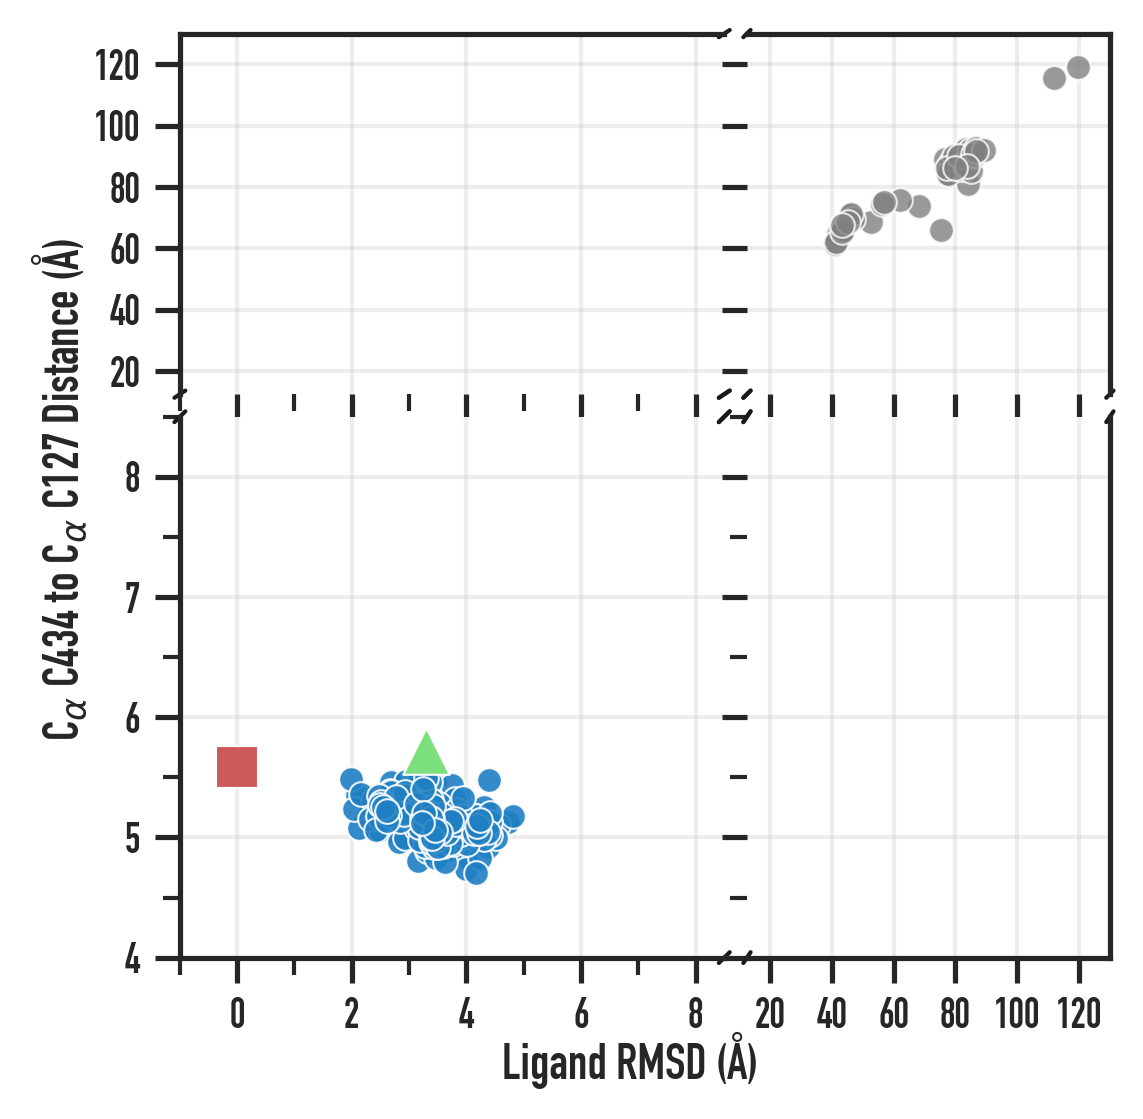

In [346]:
highlight_models = set(clusters_dic[14]) | set(clusters_dic[15])

plot_distance_pair_broken_xy(
    df_x=Cys434toCys127_rmsd_df,
    xcol="ligand_RMSD",
    df_y=df_Cys434toCys127_all_glob,
    ycol="Cys434toCys127_distance",
    xlims=((-1, 8.5), (12.5, 130)),
    ylims=((4, 8.5), (12.5, 130)),
    highlight_models=highlight_models,
    fig_w = 4, fig_h = 4,
    xlabel="Ligand RMSD (Å)",
    fig_title="LigandRMSD vs C434toC127 (Over Recog) - Constant Fab",
    ylabel="C$_\\alpha$ C434 to C$_\\alpha$ C127 Distance (Å)",
    set_fig_title=False,
    savefig=True,
    # set_legend=True,
)

In [ ]:
def plot_cluster_legend(
    precat_size=125,
    recog_size=100,
    af3_size=35,
    fig_w=2.5,
    fig_h=1.5,
):
    from matplotlib.lines import Line2D
    palette = {
        "Precatalytic": "#7ce07c",
        "Recognition": "#cc5a5c",
    }

    handles = [
        Line2D([0], [0],marker="o",color="w",
        label="AF3 Protease-driven",markerfacecolor="#1f7fc3",markeredgecolor="white",markersize=np.sqrt(af3_size),),
        Line2D([0], [0],marker="o",color="w",
        label="AF3 Fab-driven",markerfacecolor="gray",markeredgecolor="white",markersize=np.sqrt(af3_size),),
        Line2D([0], [0],marker="^",color="w",
        label="Precatalytic",markerfacecolor=palette["Precatalytic"],markeredgecolor="white",markersize=np.sqrt(precat_size) * 0.85,),
        Line2D([0], [0],marker="s",color="w",
        label="Recognition",markerfacecolor=palette["Recognition"],markeredgecolor="white",markersize=np.sqrt(recog_size) * 0.85,),]

    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.axis("off")

    ax.legend(
        handles=handles,
        loc="center",
        frameon=False,
        fontsize=10,
        ncol=4,
    )

    plt.tight_layout()
    plt.savefig("cluster_legend.png", dpi=350, bbox_inches="tight")
    plt.savefig("cluster_legend.pdf", dpi=350, bbox_inches="tight")
    plt.show()

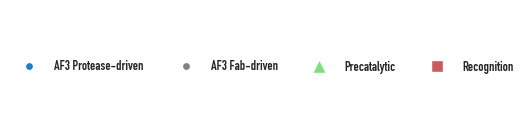

In [348]:
plot_cluster_legend(fig_w=3.5, fig_h=1.5)